# 07 · Major opportunities — are the flagged moments the right ones?

`football_eval/opportunities.py` groups shots, goals, penalties, box entries and set pieces into **attacking
moves** and flags (⚑) the ones worth watching first: goals, penalties, big chances (xG ≥ 0.30), shots on target and
shots with xG ≥ 0.10 (rules: `docs/STATS_RULEBOOK.md` §7c). The report lists them at the top with a clip and a link
to the moment in the full video; the launcher plays them next to the list.

Questions, on synthetic matches with ground truth (same generator as notebook 02):

1. **Coverage** — is every true goal inside a flagged opportunity, and every true shot inside some opportunity?
2. **Precision** — does each flagged opportunity contain a real shot or goal?
3. **Time saved** — how many minutes of video do the flagged clips add up to?
4. **Sensitivity** — what the two main settings (`flag_min_xg`, `merge_window_s`) change.
5. **Real recording** — what the list looks like on the 10-minute Canedo segment (2–5 px ball).

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import copy
from football_eval.synthetic import SyntheticMatch, SynthConfig
from football_eval.config import load_config
from football_eval.analytics import run_analytics
from football_eval.opportunities import build_opportunities, evaluate_opportunities, opportunity_plot, CATEGORIES
from football_eval.xg import XGModel
XGM = XGModel.load(ROOT / "models/xg_model.json")

def run(seed=0, period_s=900, **noise):
    m = SyntheticMatch(SynthConfig(seed=seed, period_s=period_s, **noise)).generate()
    r = run_analytics(m["tracks"], m["ball"], load_config(), root=str(ROOT))
    return m, r

def rebuild(r, **opp):
    cfg = load_config(opportunities=opp)
    return build_opportunities(r["events"], r["ctx"], cfg, XGM, r["touches"])

## 1 · One match in detail

In [2]:
m, r = run(seed=0)
opps = r["opportunities"]
minutes = sum(b - a for a, b in r["ctx"].periods) / 60
print(f"{len(opps)} opportunities, {int(opps.flag.sum())} flagged, in {minutes:.0f} min of play")
pd.DataFrame(evaluate_opportunities(opps, m["gt_events"], match_minutes=minutes), index=["seed 0"]).round(3)

24 opportunities, 13 flagged, in 30 min of play


,n_opps,n_flagged,gt_shots,gt_goals,shot_recall,goal_recall_flag,on_target_recall_flag,flag_precision,watch_min,watch_share
seed 0,24,13,26,5,0.885,1.0,1.0,1.0,3.23,0.107


In [3]:
opps[opps.flag][["video_time", "clock", "team_name", "category", "chance_xg", "danger", "description"]]

,video_time,clock,team_name,category,chance_xg,danger,description
3,02:26,3',Team B,Goal,0.142,100.0,"Goal — Team B: shot from 15 m, goal — best xG 0.14 (after a carry into the box)"
4,04:25,5',Team A,Goal,0.052,100.0,"Goal — Team A: shot from 23 m, goal — best xG 0.05"
5,05:44,6',Team B,Shot on target,0.023,12.3,"Shot on target — Team B: shot from 27 m, saved — best xG 0.02"
6,08:46,9',Team A,Shot on target,0.091,19.1,"Shot on target — Team A: shot from 19 m, saved — best xG 0.09"
7,09:20,10',Team A,Shot,0.104,10.4,"Shot — Team A: shot from 18 m, off target — best xG 0.10 (after a free kick)"
10,11:44,12',Team B,Shot on target,0.026,12.6,"Shot on target — Team B: shot from 27 m, saved — best xG 0.03"
11,11:52,12',Team B,Big chance,0.647,74.7,"Big chance — Team B: shot from 4 m, saved — best xG 0.65"
12,12:00,12',Team B,Goal,NaN,100.0,Goal — Team B: goal
13,13:04,14',Team B,Goal,0.026,100.0,"Goal — Team B: shot from 25 m, goal — best xG 0.03"
14,18:16,48',Team A,Goal,0.057,100.0,"Goal — Team A: shot from 22 m, goal — best xG 0.06"


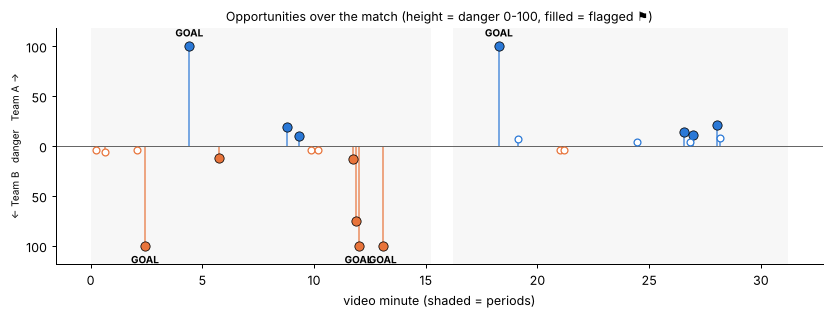

In [4]:
opportunity_plot(opps, r["ctx"])

In [5]:
pd.crosstab(opps.category, opps.team_name).reindex(CATEGORIES).fillna(0).astype(int)

team_name,Team A,Team B
category,,
Goal,2,3
Penalty,0,0
Big chance,0,1
Shot on target,4,2
Shot,5,6
"Box entry, no shot",0,0
Set piece near goal,0,1


## 2 · Benchmark: several matches, default and heavy noise

Heavy noise = 0.8 m position jitter, 25 % ball dropouts, ID switches every 30 s, goalkeepers not labelled
(the stress setting of notebook 02).

In [6]:
rows = []
for label, noise in [("default", {}), ("heavy noise", dict(noise_player_m=0.8, noise_ball_m=0.8, ball_dropout=0.25,
                                                          fragment_s=30, label_goalkeepers=False))]:
    for seed in range(1, 5):
        m_, r_ = run(seed=seed, period_s=600, **noise)
        mins = sum(b - a for a, b in r_["ctx"].periods) / 60
        e = evaluate_opportunities(r_["opportunities"], m_["gt_events"], match_minutes=mins)
        e.update(setting=label, seed=seed, minutes=mins); rows.append(e)
bench = pd.DataFrame(rows)
cols = ["n_opps", "n_flagged", "gt_shots", "gt_goals", "shot_recall", "goal_recall_flag", "on_target_recall_flag",
        "flag_precision", "watch_min", "watch_share"]
summary = bench.groupby("setting")[cols].agg(lambda s: s.sum() if s.name in ("n_opps", "n_flagged", "gt_shots", "gt_goals", "watch_min") else s.mean())
summary.round(3)

,n_opps,n_flagged,gt_shots,gt_goals,shot_recall,goal_recall_flag,on_target_recall_flag,flag_precision,watch_min,watch_share
setting,,,,,,,,,,
default,73,36,71,13,0.877,1.000,0.972,1.0,9.387,0.116
heavy noise,56,25,71,13,0.650,0.833,0.597,1.0,7.075,0.087


## 3 · Sensitivity of the two main settings (seed 0, events unchanged — only the grouping / flag rule)

In [7]:
rows = []
for fx in (0.0, 0.05, 0.10, 0.20, 0.30):
    o = rebuild(r, flag_min_xg=fx)
    e = evaluate_opportunities(o, m["gt_events"], match_minutes=minutes); e["flag_min_xg"] = fx; rows.append(e)
sens_flag = pd.DataFrame(rows).set_index("flag_min_xg")[["n_flagged", "flag_precision", "on_target_recall_flag", "watch_min"]]
rows = []
for w in (0, 3, 6, 10, 15):
    o = rebuild(r, merge_window_s=w)
    e = evaluate_opportunities(o, m["gt_events"], match_minutes=minutes); e["merge_window_s"] = w; rows.append(e)
sens_merge = pd.DataFrame(rows).set_index("merge_window_s")[["n_opps", "n_flagged", "shot_recall", "flag_precision", "watch_min"]]
sens_flag.round(3)

,n_flagged,flag_precision,on_target_recall_flag,watch_min
flag_min_xg,,,,
0.00,23,1.0,1.0,5.612
0.05,16,1.0,1.0,3.983
0.10,13,1.0,1.0,3.230
0.20,12,1.0,1.0,2.932
0.30,12,1.0,1.0,2.932


In [8]:
sens_merge.round(3)

,n_opps,n_flagged,shot_recall,flag_precision,watch_min
merge_window_s,,,,,
0,26,13,0.885,1.0,3.198
3,25,13,0.885,1.0,3.230
6,24,13,0.885,1.0,3.230
10,21,11,0.885,1.0,3.353
15,19,11,0.885,1.0,3.522


## 4 · Real recording: the 10-minute Canedo segment

Shots on this footage come from a 2–5 px ball (`docs/RECORDING_PROFILE.md` §3), so the shot detector rarely
fires. On this segment it finds a single blocked shot from 28 m (xG 0.02, not flagged), and the ball track is too
sparse for box entries. On club recordings, the flagged list depends on the review UI's key-event step. Confirm or
reject each detected shot, and **add the missed chances under "Missing events"**. Each added shot, goal or penalty
becomes a flagged opportunity with its clip on the next analytics run.

In [9]:
from football_eval.perception import load_perception
from football_eval.config import load_config
seg = ROOT / "outputs/canedo_segment"
if (seg / "tracks.csv").exists():
    cfg = load_config(ROOT / "configs/canedo_segment.yaml")
    res = load_perception(str(seg))
    rr = run_analytics(res["tracks"], res["ball"], cfg, root=str(ROOT))
    o = rr["opportunities"]
    print(f"{len(o)} opportunities, {int(o.flag.sum())} flagged")
    print(o[["video_time", "team_name", "category", "flag", "danger", "description"]].head(20).to_string(index=False))
else:
    print("outputs/canedo_segment not found — run configs/canedo_segment.yaml first")

1 opportunities, 0 flagged
video_time team_name category  flag  danger                                              description
     18:02 Canedo FC     Shot False     1.7 Shot — Canedo FC: shot from 28 m, blocked — best xG 0.02


## 5 · Take-aways

* **Default noise (4 synthetic matches, 71 true shots, 13 goals):**
  * every true goal and 97 % of the true shots on target fall inside a flagged opportunity;
  * every flagged opportunity contains a real shot or goal (precision 1.0);
  * the flagged clips add up to ~12 % of the playing time, so the chances of a 90-minute game take about 10 minutes to watch.
* **Heavy noise:** coverage drops to 83 % of the goals and 60 % of the shots on target, while precision stays at
  1.0. The list misses chances when the shot detector misses them; it does not invent chances. This is why the
  review UI's "missing events" step matters on real footage.
* **Settings:**
  * `flag_min_xg` between 0.10 and 0.30 changes little, because most flagged moves are goals or shots on target.
    0.05 adds a few long-range attempts, and 0 flags every shot (+75 % watch time).
  * With `merge_window_s` ≥ 10 s, separate attacks start to merge. 6 s keeps a corner → shot → rebound together
    without merging separate attacks.